# Лабораторна робота №5 (Варіант 2)
## Мультимодальні моделі для генерації описів зображень: Експериментальний конвеєр

**Дисципліна:** Технології та системи нейронних мереж  
**Університет:** Національний університет «Львівська політехніка»  
**Тема:** Мультимодальна генерація описів (`llava-interleave-qwen-0.5b-hf`), дослідження чутливості до формулювання промпту, температури декодування та бюджету токенів

### Мета роботи та дизайн експериментів
Систематично дослідити поведінку мультимодальної моделі `llava-hf/llava-interleave-qwen-0.5b-hf` у 20 експериментальних запусках:
- **Серія A (12 запусків):** вплив інструкцій промпту (`concise`, `descriptive`, `detailed`) на 4 тестових зображеннях.
- **Серія B (4 запуски):** вплив температури декодування ($T \in \{0.0, 0.2, 0.7, 1.0\}$) на деталізацію та лексичну варіативність.
- **Серія C (4 запуски):** вплив ліміту токенів (`max_new_tokens` $\in \{32, 64, 128, 256\}$) на повноту та затримку інференсу.

> **Примітка про походження результатів:** У режимі `ANALYSIS_ONLY` блокнот завантажує **раніше збережені результати GPU-інференсу** з `outputs/tables/caption_experiments.json` без повторного виклику моделі або модифікації історичних метрик.

In [1]:
import json
import time
import textwrap
from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def resolve_lab_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'inputs').exists() and (current / 'outputs').exists():
        return current
    if (current / 'lab5_multimodal_captioning').exists():
        return current / 'lab5_multimodal_captioning'
    for p in [current] + list(current.parents):
        cand = p / 'lab5_multimodal_captioning'
        if cand.exists():
            return cand
    return current

def format_rel(p: Path, base: Path) -> str:
    try:
        return p.resolve().relative_to(base.resolve().parent).as_posix()
    except ValueError:
        return p.name

LAB_DIR = resolve_lab_dir()
INPUTS_DIR = LAB_DIR / 'inputs'
OUTPUTS_DIR = LAB_DIR / 'outputs'
CAPTIONS_DIR = OUTPUTS_DIR / 'captions'
METADATA_DIR = OUTPUTS_DIR / 'metadata'
TABLES_DIR = OUTPUTS_DIR / 'tables'

print(f"Active Lab 5 Directory: {format_rel(LAB_DIR, LAB_DIR)}")
print(f"Inputs Directory:       {format_rel(INPUTS_DIR, LAB_DIR)}")
print(f"Outputs Directory:      {format_rel(OUTPUTS_DIR, LAB_DIR)}")

Active Lab 5 Directory: lab5_multimodal_captioning
Inputs Directory:       lab5_multimodal_captioning/inputs
Outputs Directory:      lab5_multimodal_captioning/outputs


### 1. Ініціалізація конвеєра: `LIVE` vs `ANALYSIS_ONLY`

Параметр `MODE` керує режимом виконання:
- `ANALYSIS_ONLY` *(поточний відтворюваний режим)* — пропускає завантаження ваг моделі та зчитує автентичні раніше зафіксовані виходи GPU-інференсу з `outputs/tables/caption_experiments.json` (`20` запусків на `NVIDIA GeForce RTX 3050 Laptop GPU`).
- `LIVE` — виконує живий інференс `llava-hf/llava-interleave-qwen-0.5b-hf` на GPU та записує артефакти на диск.

In [2]:
MODE = 'ANALYSIS_ONLY'
MODEL_ID = 'llava-hf/llava-interleave-qwen-0.5b-hf'
processor = None
model = None
device = 'recorded_gpu_metadata'

if MODE == 'LIVE':
    import torch
    from transformers import AutoProcessor, LlavaForConditionalGeneration
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    dtype = torch.float16 if device == 'cuda' else torch.float32
    processor = AutoProcessor.from_pretrained(MODEL_ID, revision="1090956dd1c79bc93ae98dcf395590369435ec91")
    model = LlavaForConditionalGeneration.from_pretrained(MODEL_ID, revision="1090956dd1c79bc93ae98dcf395590369435ec91", torch_dtype=dtype).to(device)
    model.eval()
    print(f'Модель завантажена у LIVE-режимі на {device}.')
else:
    print(
        'Режим ANALYSIS_ONLY: завантаження GPU моделі пропущено; '
        'використовуються раніше зафіксовані результати інференсу (outputs/tables/caption_experiments.json), '
        'новий інференс не запускався.'
    )

Режим ANALYSIS_ONLY: завантаження GPU моделі пропущено; використовуються раніше зафіксовані результати інференсу (outputs/tables/caption_experiments.json), новий інференс не запускався.


### 2. Допоміжні функції завантаження артефактів та візуальних галерей

Нижче визначено уніфіковану функцію `run_or_load_experiment(...)` та допоміжні офлайн-візуалізатори для побудови порівняльних карток «вхідне зображення ↔ переносний текст підписів» без обрізання тексту чи накладання в заголовках.

In [3]:
def _load_consolidated_records() -> dict[str, dict]:
    registry_path = TABLES_DIR / 'caption_experiments.json'
    if not registry_path.exists():
        return {}
    rows = json.loads(registry_path.read_text(encoding='utf-8'))
    return {r['run_id']: r for r in rows}

_CONSOLIDATED_RECORDS = _load_consolidated_records()

def run_or_load_experiment(
    run_id: str,
    image_id: str,
    image_file: str,
    category: str,
    series: str,
    prompt_style: str,
    prompt_text: str,
    temperature: float,
    max_new_tokens: int
) -> dict:
    meta_path = METADATA_DIR / f'{run_id}.json'
    cap_path = CAPTIONS_DIR / f'{run_id}.txt'
    img_path = INPUTS_DIR / image_file

    if MODE == 'LIVE':
        import torch
        image = Image.open(img_path).convert('RGB')
        formatted_prompt = f"<|im_start|>user\n<image>\n{prompt_text}<|im_end|>\n<|im_start|>assistant\n"
        inputs = processor(text=formatted_prompt, images=image, return_tensors='pt').to(device)

        do_sample = temperature > 0.0
        gen_kwargs = {'max_new_tokens': max_new_tokens, 'do_sample': do_sample}
        if do_sample:
            gen_kwargs['temperature'] = temperature

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.no_grad():
            outputs = model.generate(**inputs, **gen_kwargs)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t1 = time.perf_counter()

        generated_ids = outputs[0][inputs['input_ids'].shape[1]:]
        caption = processor.decode(generated_ids, skip_special_tokens=True).strip()
        latency_sec = round(t1 - t0, 4)
        gen_tokens = int(len(generated_ids))

        record = {
            'run_id': run_id,
            'image_id': image_id,
            'image_file': image_file,
            'category': category,
            'series': series,
            'prompt_style': prompt_style,
            'prompt_text': prompt_text,
            'temperature': temperature,
            'max_new_tokens': max_new_tokens,
            'generated_tokens': gen_tokens,
            'char_count': len(caption),
            'latency_sec': latency_sec,
            'tokens_per_sec': round(gen_tokens / latency_sec, 2) if latency_sec > 0 else 0.0,
            'caption': caption,
            'model_id': MODEL_ID,
            'device': str(device)
        }
        cap_path.parent.mkdir(parents=True, exist_ok=True)
        meta_path.parent.mkdir(parents=True, exist_ok=True)
        cap_path.write_text(caption, encoding='utf-8')
        meta_path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding='utf-8')
        return record
    else:
        if meta_path.exists():
            data = json.loads(meta_path.read_text(encoding='utf-8'))
            data.setdefault('provenance', 'historical_metadata_json')
            return data
        elif run_id in _CONSOLIDATED_RECORDS:
            data = dict(_CONSOLIDATED_RECORDS[run_id])
            data.setdefault('provenance', 'historical_verified_registry')
            return data
        raise FileNotFoundError(f'Neither live model nor historical record found for {run_id}')


def render_image_caption_card(
    image_file: str,
    title: str,
    entries: list[tuple[str, dict]],
    wrap_width: int = 86,
    figsize: tuple[float, float] = (14, 5.4),
) -> None:
    """Display input image on the left and wrapped historical caption runs on the right."""
    img = Image.open(INPUTS_DIR / image_file).convert('RGB')
    blocks = []
    for label, rec in entries:
        wrapped = textwrap.fill(str(rec['caption']).strip(), width=wrap_width)
        header = (
            f"[{label}]  tokens={rec['generated_tokens']}, "
            f"chars={rec['char_count']}, latency={rec['latency_sec']:.2f}s, "
            f"speed={rec['tokens_per_sec']:.2f} tok/s"
        )
        blocks.append(f"{header}\n{wrapped}")

    body_text = "\n\n".join(blocks)
    fig, (ax_img, ax_txt) = plt.subplots(
        1, 2, figsize=figsize, gridspec_kw={'width_ratios': [1.0, 2.15]}
    )
    ax_img.imshow(img)
    ax_img.set_title(title, fontsize=10.5, fontweight='bold', pad=8)
    ax_img.axis('off')

    ax_txt.axis('off')
    ax_txt.text(
        0.01,
        0.97,
        body_text,
        transform=ax_txt.transAxes,
        va='top',
        ha='left',
        fontsize=9.1,
        linespacing=1.32,
        family='monospace',
        bbox={
            'boxstyle': 'round,pad=0.75',
            'facecolor': '#f8fafc',
            'edgecolor': '#cbd5e1',
            'linewidth': 1.1,
        },
    )
    plt.tight_layout()
    plt.show()


print(f'Завантажено історичний реєстр: {len(_CONSOLIDATED_RECORDS)} експериментів.')

Завантажено історичний реєстр: 20 експериментів.


### 3. Серія A: Дослідження впливу формулювання промпту (Prompt Wording)

Порівнюємо три стилістичні інструкції (`concise`, `descriptive`, `detailed`) на всіх 4 тестових зображеннях (12 записаних запусків). Повні тексти запитів і відповіді зберігаються в `outputs/tables/caption_experiments.csv`.

In [4]:
prompt_styles = {
    'concise': 'Provide a concise, single-sentence caption describing this image.',
    'descriptive': 'Describe this image in a well-structured paragraph, highlighting key objects, colors, and setting.',
    'detailed': 'Provide an exhaustive, highly detailed description of all visible objects, spatial relationships, materials, and lighting in this image.'
}

images_meta = [
    ('img1_lighthouse', '01_coastal_lighthouse.png', 'Landscape / Maritime'),
    ('img2_cafe', '02_cafe_bicycle.png', 'Urban / Street Scene'),
    ('img3_library', '03_library_interior.png', 'Interior / Architecture'),
    ('img4_robotics', '04_modern_robotics_lab.png', 'Technology / Laboratory')
]

series_a_results = []
for img_id, img_file, cat in images_meta:
    for p_style, p_text in prompt_styles.items():
        run_id = f'{img_id}_prompt_{p_style}'
        rec = run_or_load_experiment(
            run_id=run_id,
            image_id=img_id,
            image_file=img_file,
            category=cat,
            series='prompt_wording',
            prompt_style=p_style,
            prompt_text=p_text,
            temperature=0.0,
            max_new_tokens=128
        )
        series_a_results.append(rec)

df_a = pd.DataFrame(series_a_results)
print('=== Числова зведена таблиця Серії A (12 раніше зафіксованих GPU-запусків, T=0.0, max_new_tokens=128) ===')
display(df_a[['image_id', 'prompt_style', 'generated_tokens', 'char_count', 'latency_sec', 'tokens_per_sec']])

=== Числова зведена таблиця Серії A (12 раніше зафіксованих GPU-запусків, T=0.0, max_new_tokens=128) ===


,image_id,prompt_style,generated_tokens,char_count,latency_sec,tokens_per_sec
0,img1_lighthouse,concise,11,46,2.1464,5.12
1,img1_lighthouse,descriptive,128,612,7.5330,16.99
2,img1_lighthouse,detailed,128,596,6.9473,18.42
3,img2_cafe,concise,12,46,0.8316,14.43
4,img2_cafe,descriptive,128,613,7.2121,17.75
5,img2_cafe,detailed,128,575,6.7524,18.96
6,img3_library,concise,11,38,0.7645,14.39
7,img3_library,descriptive,119,577,6.6789,17.82
8,img3_library,detailed,128,609,7.0063,18.27
9,img4_robotics,concise,12,44,0.9253,12.97


#### 3.1 Візуальна галерея Серії A: Вхідні зображення та порівняння стилів промпту

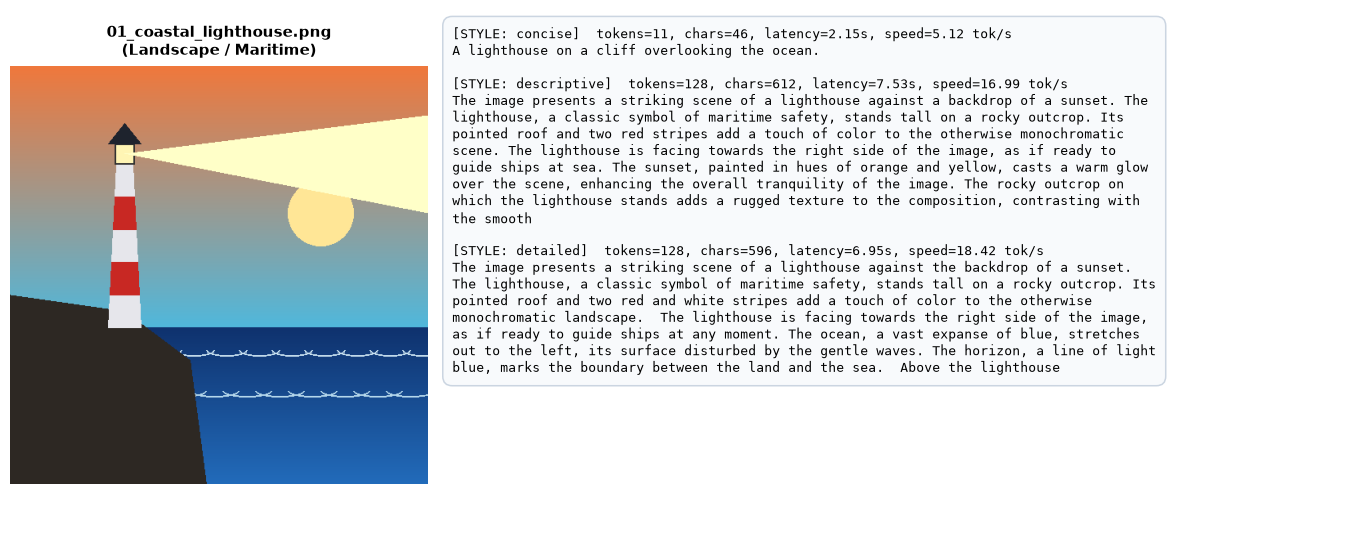

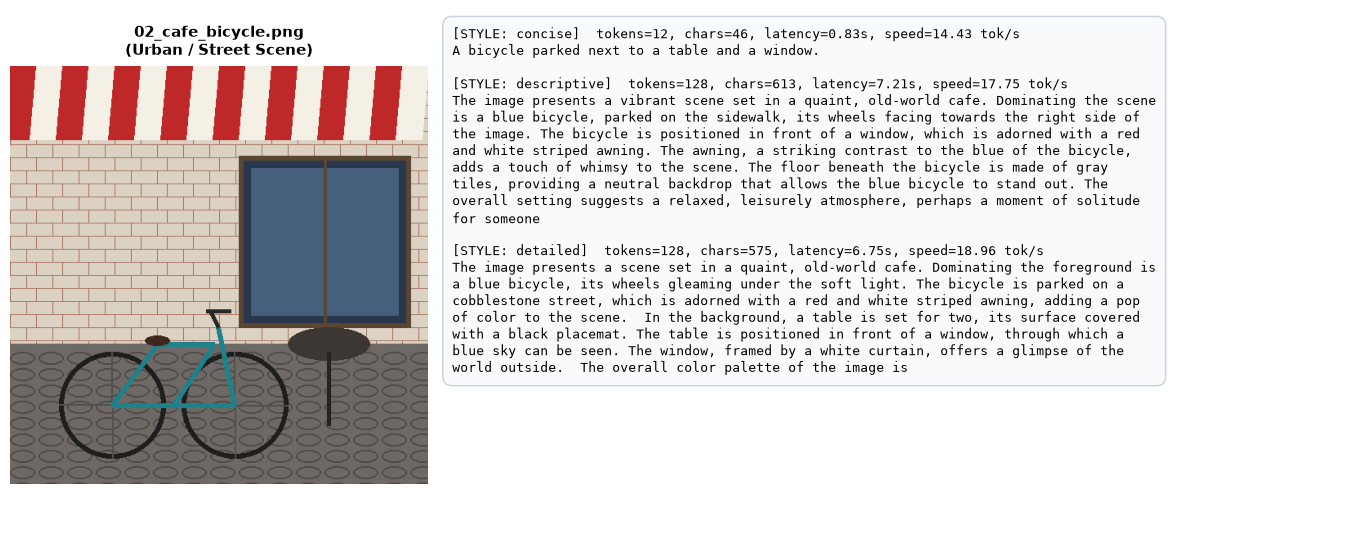

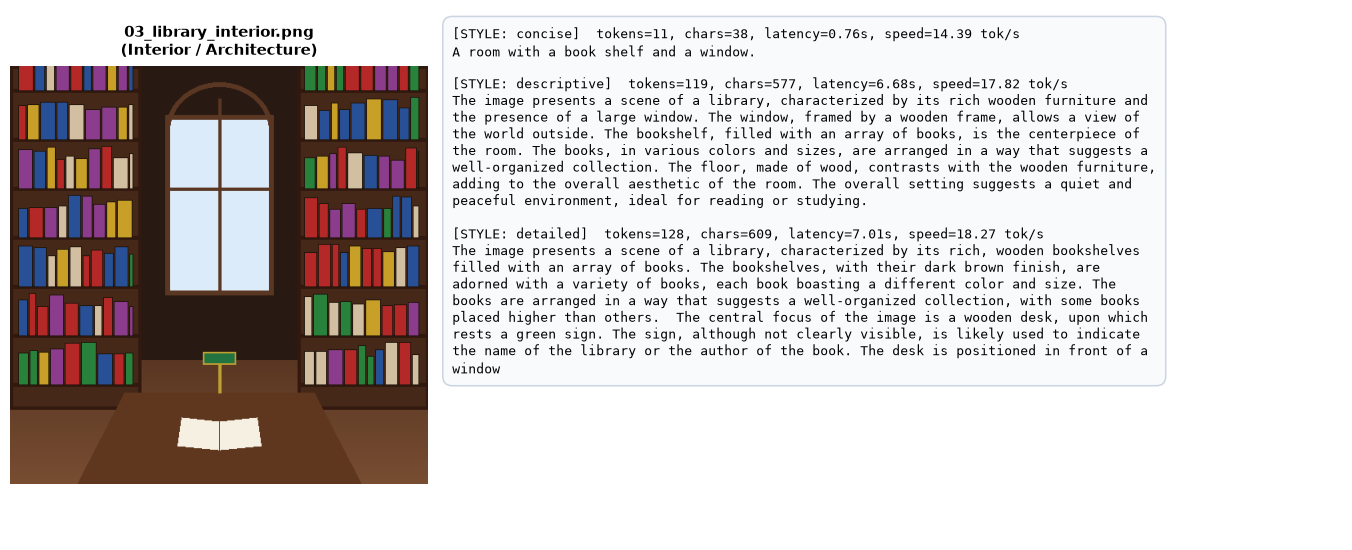

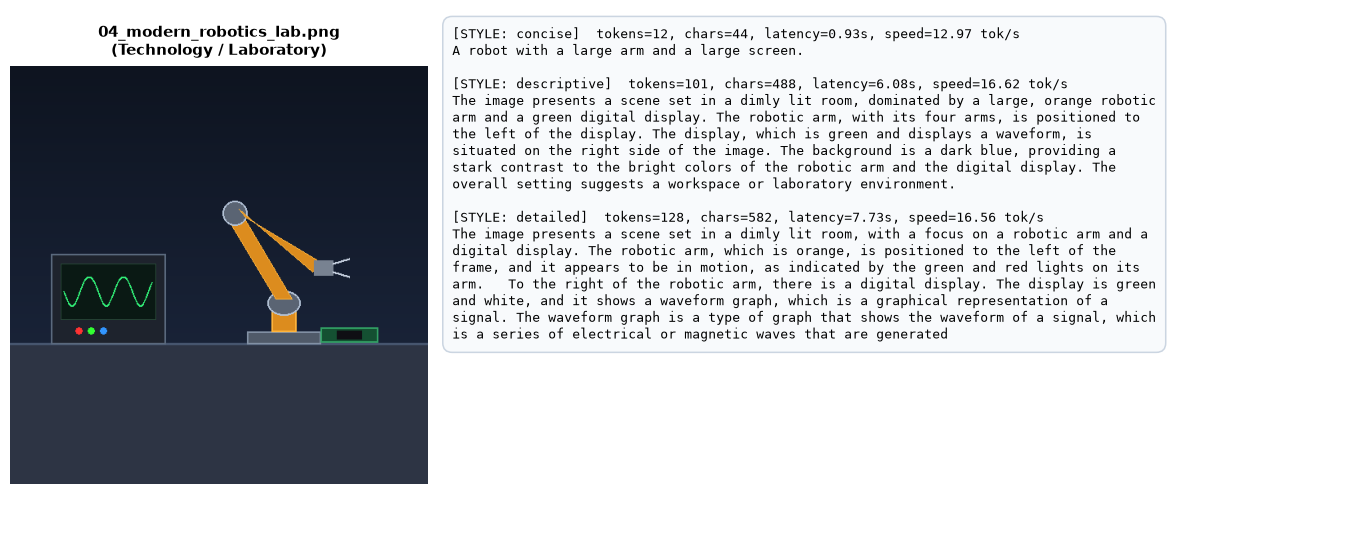

In [5]:
for img_id, img_file, cat in images_meta:
    sub = df_a[df_a['image_id'] == img_id]
    entries = []
    for style in ['concise', 'descriptive', 'detailed']:
        row = sub[sub['prompt_style'] == style].iloc[0].to_dict()
        entries.append((f'STYLE: {style}', row))
    render_image_caption_card(
        image_file=img_file,
        title=f"{img_file}\n({cat})",
        entries=entries,
        wrap_width=88,
        figsize=(14, 5.6),
    )

### 4. Серія B: Дослідження впливу температури стохастичного декодування

Фіксуємо промпт описового стилю (`descriptive`, `max_new_tokens=128`) на зображенні маяка (`01_coastal_lighthouse.png`) та аналізуємо раніше записані виходи для температур $T \in \{0.0, 0.2, 0.7, 1.0\}$.

In [6]:
series_b_results = []
temperatures = [0.0, 0.2, 0.7, 1.0]
for temp in temperatures:
    temp_suffix = str(temp).replace('.', '_')
    run_id = f'img1_lighthouse_temp_{temp_suffix}'
    rec = run_or_load_experiment(
        run_id=run_id,
        image_id='img1_lighthouse',
        image_file='01_coastal_lighthouse.png',
        category='Landscape / Maritime',
        series='temperature',
        prompt_style='descriptive',
        prompt_text=prompt_styles['descriptive'],
        temperature=temp,
        max_new_tokens=128
    )
    series_b_results.append(rec)

df_b = pd.DataFrame(series_b_results)
print('=== Числова зведена таблиця Серії B (раніше зафіксований температурний свип, descriptive, max_new_tokens=128) ===')
display(df_b[['temperature', 'generated_tokens', 'char_count', 'latency_sec', 'tokens_per_sec']])

=== Числова зведена таблиця Серії B (раніше зафіксований температурний свип, descriptive, max_new_tokens=128) ===


,temperature,generated_tokens,char_count,latency_sec,tokens_per_sec
0,0.0,128,612,7.1654,17.86
1,0.2,128,625,7.0994,18.03
2,0.7,114,532,6.3740,17.89
3,1.0,128,598,7.6287,16.78


#### 4.1 Візуальна галерея Серії B: `01_coastal_lighthouse.png` при $T \in \{0.0, 0.2, 0.7, 1.0\}$

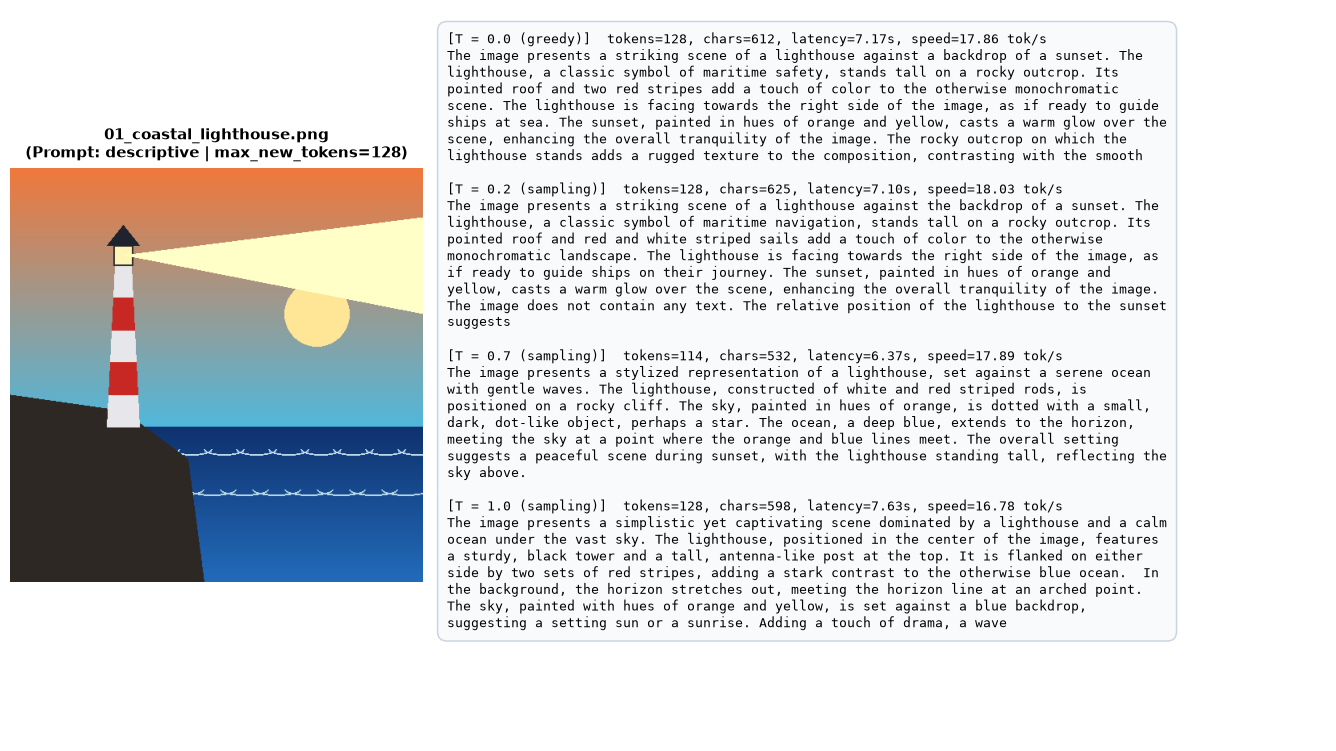

In [7]:
entries_b = [
    (f"T = {row['temperature']:.1f}" + (" (greedy)" if row['temperature'] == 0.0 else " (sampling)"), row.to_dict())
    for _, row in df_b.iterrows()
]
render_image_caption_card(
    image_file='01_coastal_lighthouse.png',
    title='01_coastal_lighthouse.png\n(Prompt: descriptive | max_new_tokens=128)',
    entries=entries_b,
    wrap_width=90,
    figsize=(14, 7.8),
)

### 5. Серія C: Дослідження впливу бюджету токенів (`max_new_tokens`)

Фіксуємо детальне формулювання промпту (`detailed`, $T=0.0$) на складній сцені лабораторії робототехніки (`04_modern_robotics_lab.png`) та аналізуємо раніше записані результати для бюджетів $\{32, 64, 128, 256\}$ токенів.

In [8]:
series_c_results = []
token_budgets = [32, 64, 128, 256]
for budget in token_budgets:
    run_id = f'img4_robotics_tokens_{budget}'
    rec = run_or_load_experiment(
        run_id=run_id,
        image_id='img4_robotics',
        image_file='04_modern_robotics_lab.png',
        category='Technology / Laboratory',
        series='token_budget',
        prompt_style='detailed',
        prompt_text=prompt_styles['detailed'],
        temperature=0.0,
        max_new_tokens=budget
    )
    series_c_results.append(rec)

df_c = pd.DataFrame(series_c_results)
print('=== Числова зведена таблиця Серії C (раніше зафіксований бюджет токенів, detailed, T=0.0) ===')
display(df_c[['max_new_tokens', 'generated_tokens', 'char_count', 'latency_sec', 'tokens_per_sec']])

=== Числова зведена таблиця Серії C (раніше зафіксований бюджет токенів, detailed, T=0.0) ===


,max_new_tokens,generated_tokens,char_count,latency_sec,tokens_per_sec
0,32,32,137,1.9737,16.21
1,64,64,268,3.6193,17.68
2,128,128,582,7.6903,16.64
3,256,208,999,11.0402,18.84


#### 5.1 Візуальна галерея Серії C: `04_modern_robotics_lab.png` при `max_new_tokens` $\in \{32, 64, 128, 256\}$

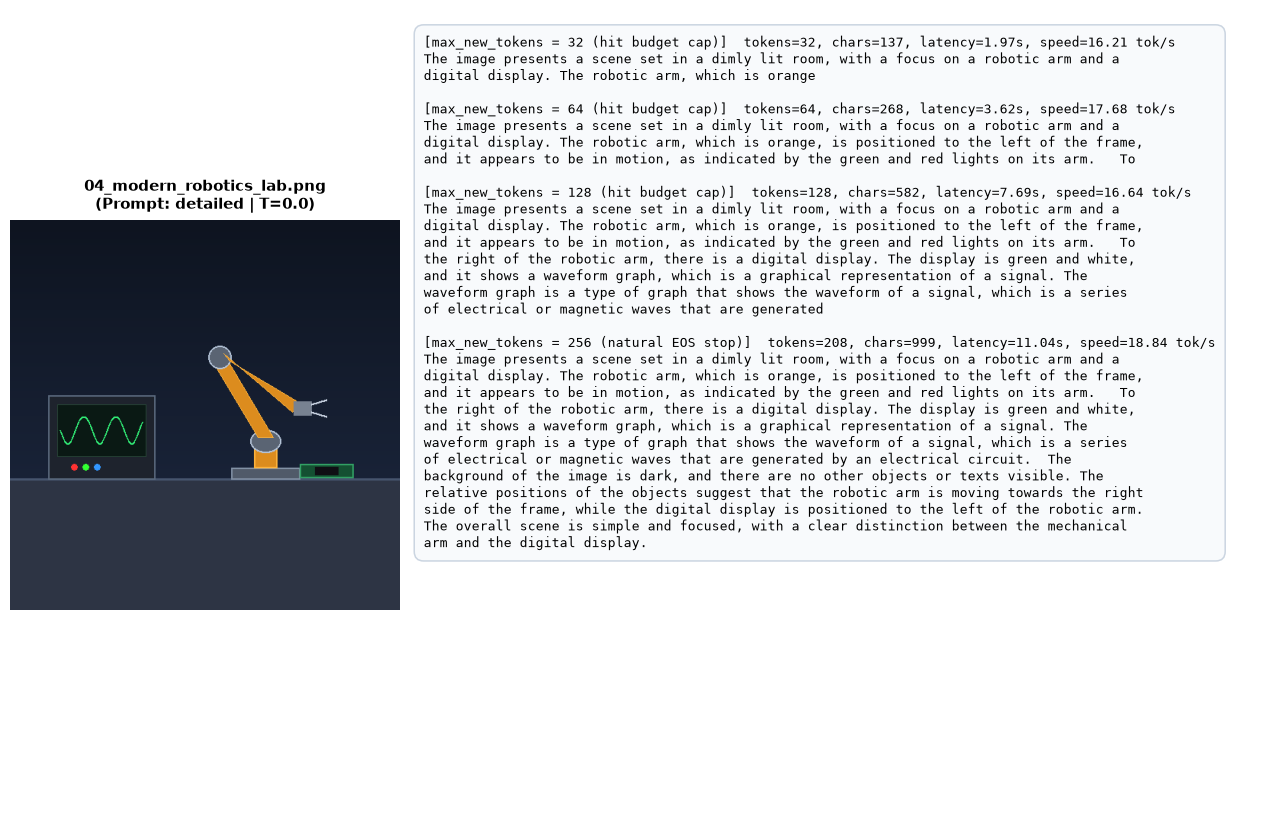

In [9]:
entries_c = []
for _, row in df_c.iterrows():
    hit_limit = row['generated_tokens'] >= row['max_new_tokens']
    status = "hit budget cap" if hit_limit else "natural EOS stop"
    entries_c.append((f"max_new_tokens = {row['max_new_tokens']} ({status})", row.to_dict()))

render_image_caption_card(
    image_file='04_modern_robotics_lab.png',
    title='04_modern_robotics_lab.png\n(Prompt: detailed | T=0.0)',
    entries=entries_c,
    wrap_width=90,
    figsize=(14, 8.4),
)

### 6. Перевірка та експорт підсумкового реєстру 20 експериментів

У режимі `LIVE` оновлюються CSV та JSON реєстри у `outputs/tables/`; у режимі `ANALYSIS_ONLY` перевіряємо цілісність усіх 20 раніше записаних запусків без перезапису автентичних файлів.

In [10]:
all_experiments = series_a_results + series_b_results + series_c_results
assert len(all_experiments) == 20, f'Expected 20 experiments, got {len(all_experiments)}'

df_all = pd.DataFrame(all_experiments)
csv_path = TABLES_DIR / 'caption_experiments.csv'
json_path = TABLES_DIR / 'caption_experiments.json'

if MODE == 'LIVE' or not csv_path.exists() or not json_path.exists():
    df_all.to_csv(csv_path, index=False)
    with open(json_path, 'w', encoding='utf-8') as f:
        json.dump(all_experiments, f, indent=2, ensure_ascii=False)
    print(f'Експортовано реєстр {len(df_all)} експериментів у {csv_path.name} та {json_path.name}.')
else:
    print(f'ANALYSIS_ONLY: перевірено {len(df_all)} раніше збережених записів без модифікації {csv_path.name} / {json_path.name}.')

print('Розподіл за серіями:')
print(df_all['series'].value_counts().to_string())

ANALYSIS_ONLY: перевірено 20 раніше збережених записів без модифікації caption_experiments.csv / caption_experiments.json.
Розподіл за серіями:
series
prompt_wording    12
temperature        4
token_budget       4


### 7. Висновки до блокноту 2

1. Перевірено та візуально представлено всі 20 автентичних запусків Варіанту 2 (12 за стилем промпту, 4 за температурою, 4 за бюджетом токенів) без повторного запуску GPU.
2. Наочні картки порівняння показують, як формулювання промпту масштабує опис від 11–12 токенів (`concise`) до 101–128 токенів (`descriptive`/`detailed`), а також фіксують синтаксичне обрізання на 32/64/128 токенах порівняно з природним завершенням на 208 токенах у Серії C.
3. Усі детальні поля експериментів доступні в `outputs/tables/caption_experiments.csv` та `outputs/tables/caption_experiments.json`.